# Student Marks Analysis

**Goal:** find which subjects have the widest spread of marks, see how grades are distributed, and measure how results changed between the midterm and the final exam.

**Dataset:** `data/student_marks.csv`, 60 students, 5 subjects, 2 exams (600 rows). The data is synthetic and generated by `scripts/generate_data.py` with a fixed seed, so every number below can be reproduced.

**Grading scale:** A+ 90 and above, A 80 to 89, B 70 to 79, C 60 to 69, Fail below 60.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.analysis import (
    load_marks, add_grades, subject_summary, grade_distribution,
    compare_exams, improvement_by_subject, student_ranking,
    plot_marks_distribution, plot_histogram, plot_grade_distribution, plot_exam_comparison,
)

FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)

## 2. Load and check the data

In [2]:
df = load_marks(ROOT / "data" / "student_marks.csv")
print(df.shape)
df.head()

(600, 5)


,student_id,subject,exam,exam_date,marks
0,S001,Math,Midterm,2024-01-10,43
1,S001,Math,Final,2024-03-15,44
2,S001,English,Midterm,2024-01-10,77
3,S001,English,Final,2024-03-15,84
4,S001,Science,Midterm,2024-01-10,81


In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Students:", df["student_id"].nunique(), "| Subjects:", df["subject"].nunique(), "| Exams:", df["exam"].nunique())
df["marks"].describe().round(1)

Missing values: 0
Duplicate rows: 0
Students: 60 | Subjects: 5 | Exams: 2


count    600.0
mean      74.6
std       14.4
min       17.0
25%       66.0
50%       76.0
75%       85.0
max      100.0
Name: marks, dtype: float64

## 3. Assign grades

In [4]:
df = add_grades(df)
df["grade"].value_counts().reindex(["A+", "A", "B", "C", "Fail"])

grade
A+       85
A       139
B       181
C       112
Fail     83
Name: count, dtype: int64

## 4. Which subject has the widest spread?

Subjects are sorted by standard deviation. A high standard deviation and a wide interquartile range (IQR) mean students' marks in that subject are far apart.

In [5]:
summary = subject_summary(df)
summary.to_csv(RESULTS / "subject_summary.csv", index=False)
summary

,subject,students,average,median,std_dev,lowest,highest,iqr,pass_rate_%,range
0,Math,120,66.5,67.0,18.7,17,100,26.2,65.8,83
1,Science,120,71.7,73.0,13.7,36,100,20.0,83.3,64
2,Computer Science,120,78.1,78.0,12.1,47,100,16.0,93.3,53
3,English,120,76.3,77.0,11.3,52,100,15.0,89.2,48
4,Urdu,120,80.6,81.5,10.0,59,100,15.0,99.2,41


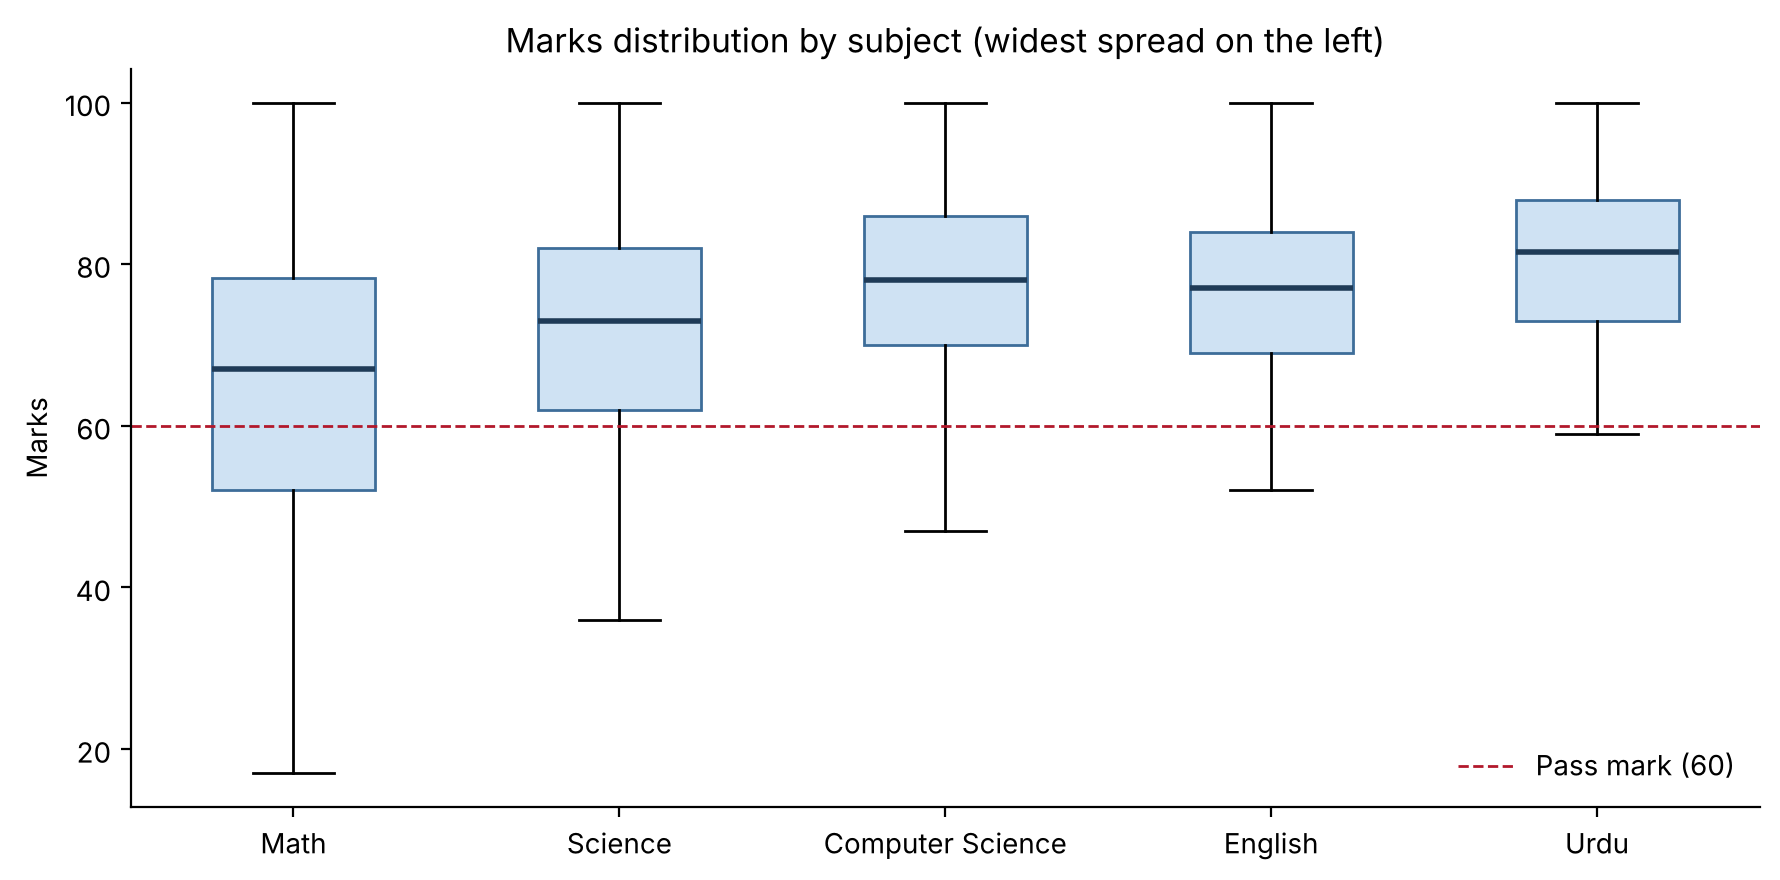

In [6]:
fig = plot_marks_distribution(df)
fig.savefig(FIGURES / "marks_distribution_by_subject.png", dpi=120)
plt.show()

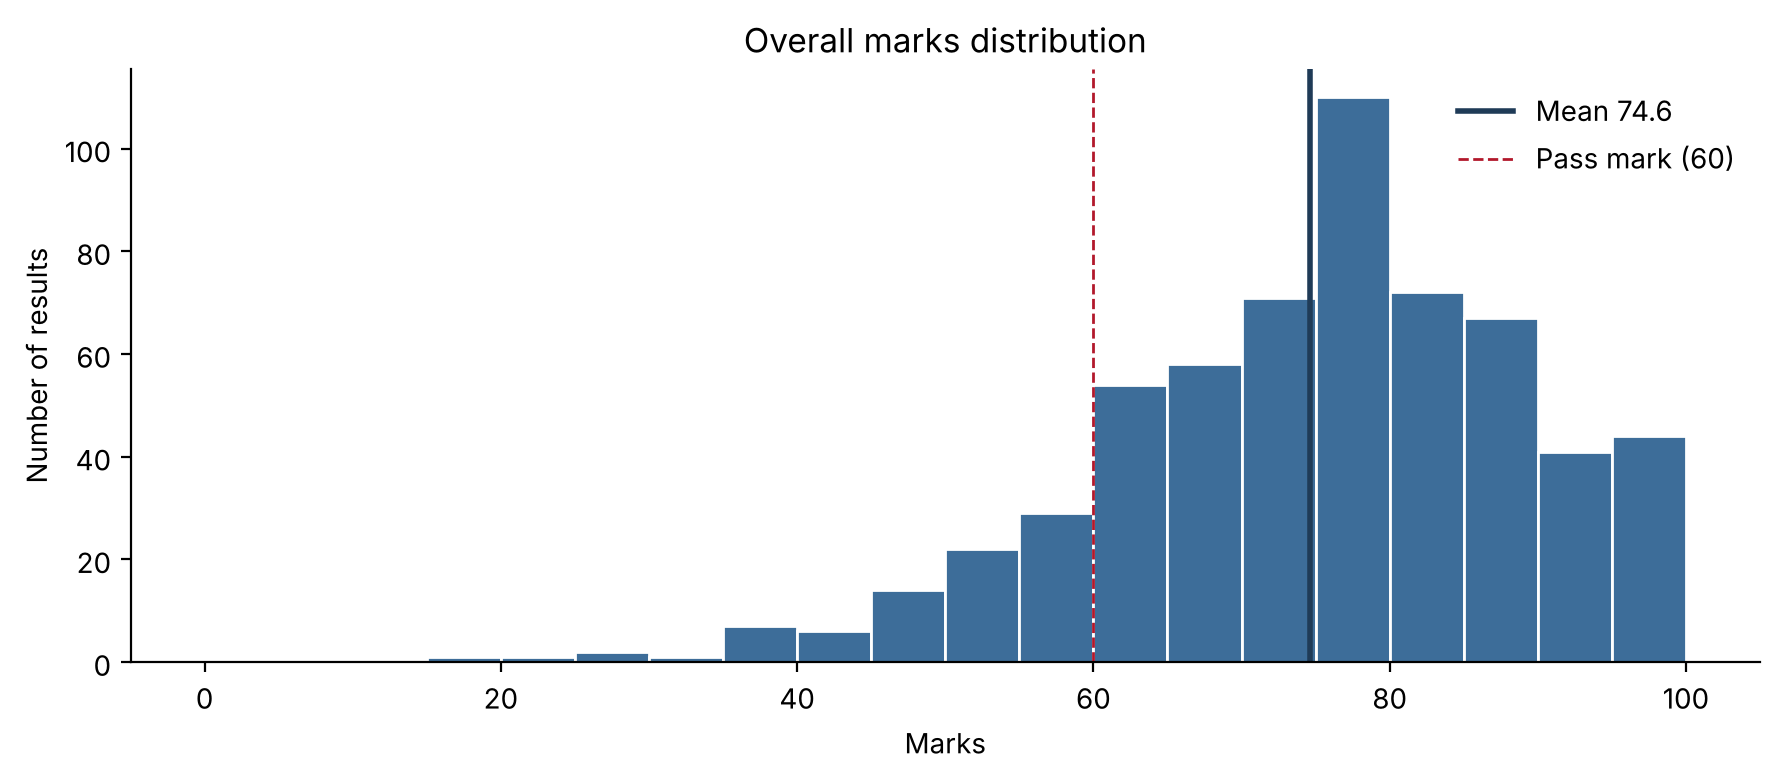

In [7]:
fig = plot_histogram(df)
fig.savefig(FIGURES / "overall_marks_histogram.png", dpi=120)
plt.show()

## 5. Grade distribution by subject

In [8]:
grade_distribution(df)

grade,A+,A,B,C,Fail
subject,,,,,
Computer Science,19.2,25.0,33.3,15.8,6.7
English,13.3,22.5,38.3,15.0,10.8
Math,11.7,11.7,20.8,21.7,34.2
Science,10.0,20.0,25.8,27.5,16.7
Urdu,16.7,36.7,32.5,13.3,0.8


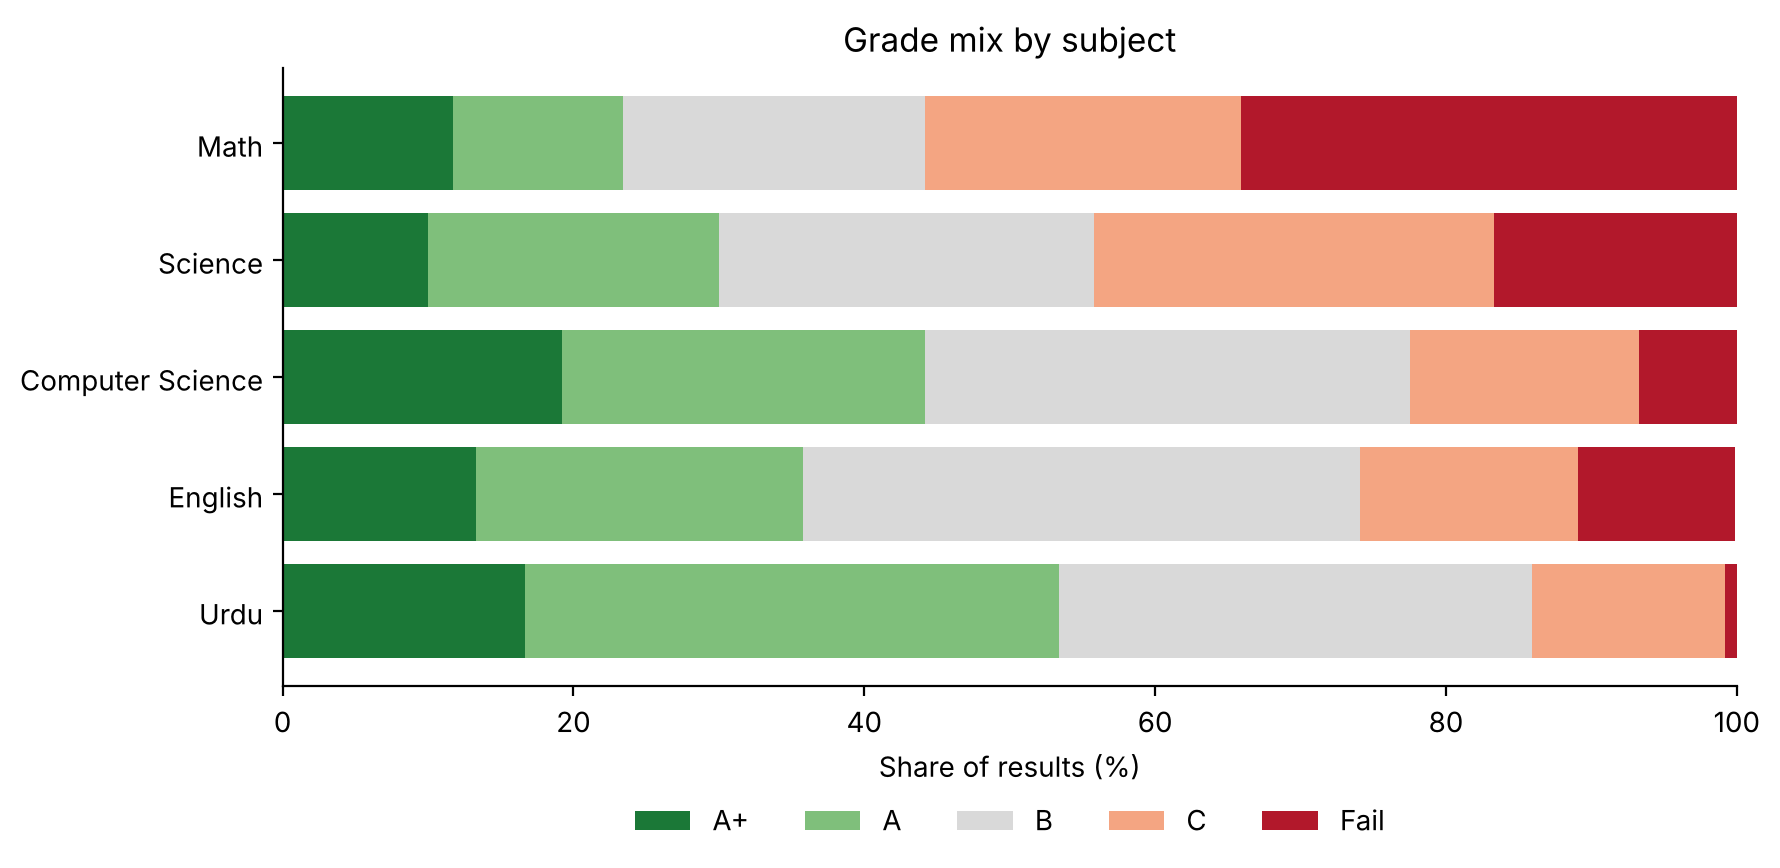

In [9]:
fig = plot_grade_distribution(df)
fig.savefig(FIGURES / "grade_mix_by_subject.png", dpi=120)
plt.show()

## 6. Midterm vs final

In [10]:
comparison = compare_exams(df)
comparison.to_csv(RESULTS / "exam_comparison.csv", index=False)
improvement = improvement_by_subject(comparison)
improvement

,subject,avg_first_exam,avg_last_exam,avg_change,improved_%
0,Urdu,79.1,82.1,3.0,66.7
1,Science,70.3,73.1,2.8,65.0
2,Computer Science,76.8,79.4,2.5,63.3
3,Math,65.4,67.7,2.4,63.3
4,English,75.4,77.2,1.9,58.3


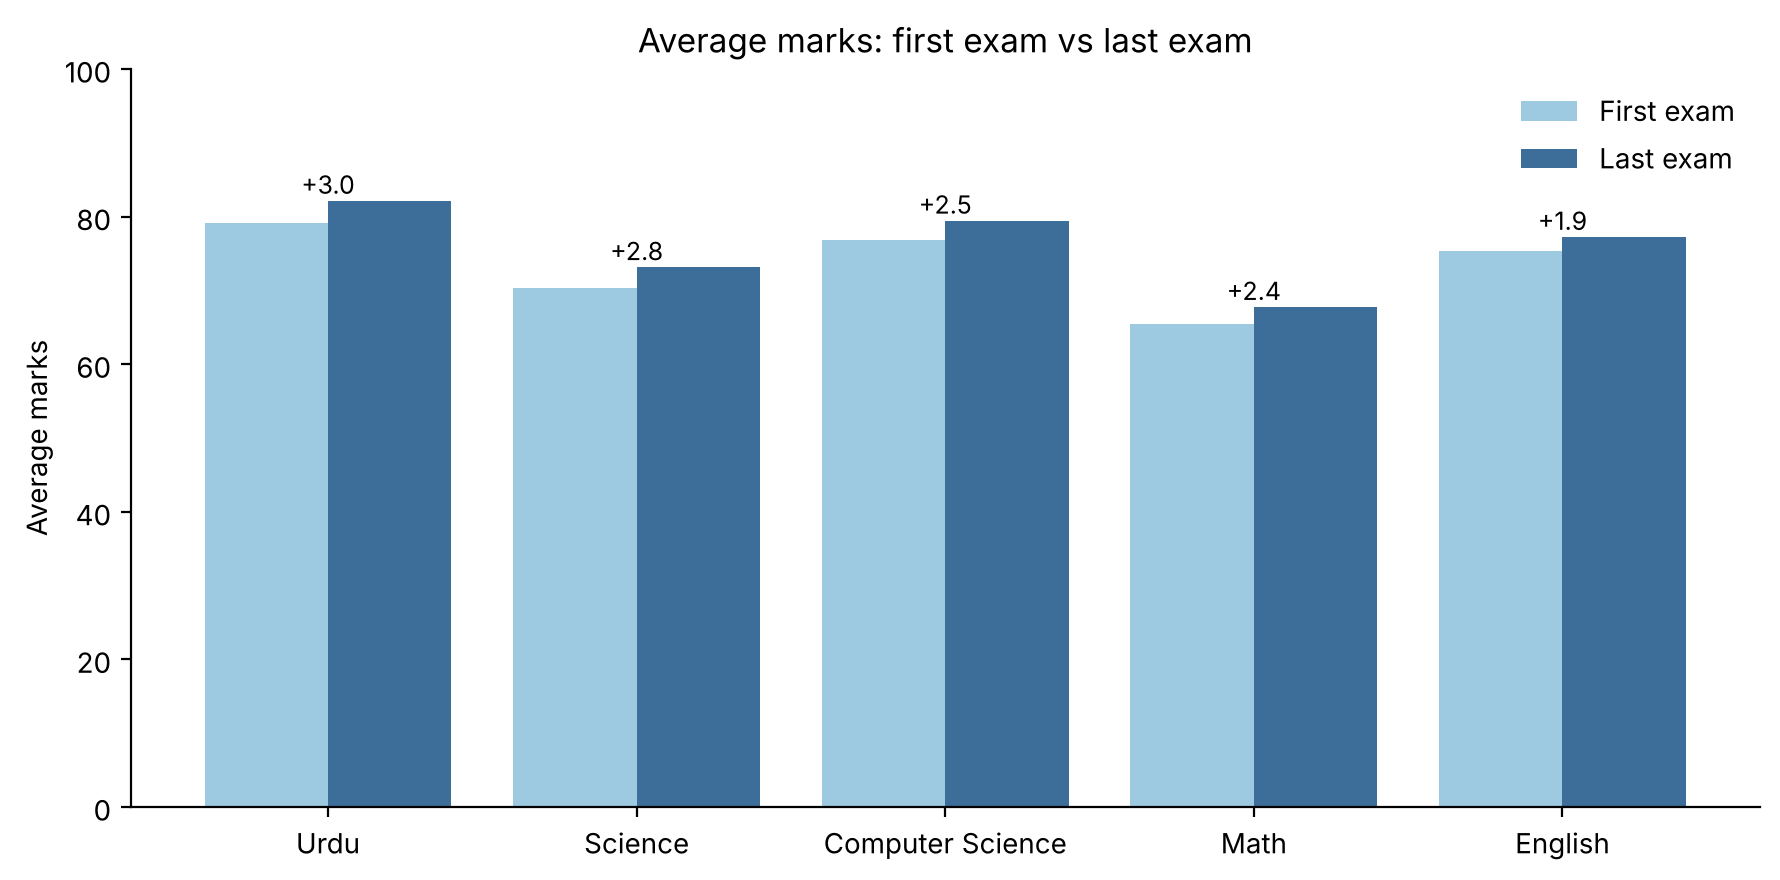

In [11]:
fig = plot_exam_comparison(improvement)
fig.savefig(FIGURES / "midterm_vs_final.png", dpi=120)
plt.show()

In [12]:
print("Students who improved overall:",
      int((comparison.groupby("student_id")["change"].mean() > 0).sum()), "of", comparison["student_id"].nunique())
print("Biggest single improvement:")
comparison.sort_values("change", ascending=False).head(3)

Students who improved overall: 56 of 60
Biggest single improvement:


,student_id,subject,first_exam,last_exam,change
209,S042,Urdu,82,100,18
157,S032,Science,75,92,17
106,S022,English,69,85,16


## 7. Student ranking (final exam)

In [13]:
ranking = student_ranking(df)
ranking.to_csv(RESULTS / "student_ranking.csv", index=False)
print("Top 5")
display(ranking.head())
print("Students failing two or more subjects:", int((ranking["subjects_failed"] >= 2).sum()))

Top 5


,rank,student_id,average,subjects_failed
0,1,S060,90.0,0
1,2,S031,89.8,0
2,3,S047,87.8,1
3,4,S040,86.6,0
4,5,S014,85.8,0


Students failing two or more subjects: 8


## 8. Findings

1. **Math has the widest spread.** Its standard deviation (18.7) and IQR (26.2) are the highest of all subjects, and marks range from 17 to 100. It also has the lowest pass rate (65.8%), with about a third of results below 60.
2. **Urdu is the most consistent subject.** It has the smallest spread (std dev 10.0) and a pass rate of 99.2%.
3. **Every subject improved from midterm to final.** Average gains range from +1.9 (English) to +3.0 (Urdu), and roughly 60 to 67% of students improved in each subject.
4. **Recommendation:** extra support in Math should target the lower half of the class, since the problem is a wide gap between students rather than a low average for everyone.

Exported results are in `reports/` and charts in `reports/figures/`.